# Практика 21. Метод Монте-Карло

**Студент:** Huz_Yurii  
**Група:** IT-41  
**Варіант:** N=3, Одеса — визначений інтеграл

Мета: оцінити інтеграл методом Монте-Карло, порівняти результат з аналітичним значенням і на серії повторів перевірити масштабування середньої абсолютної похибки як `1/√N`.

## Варіант 3: оцінка інтеграла

Потрібно оцінити

$$\int_0^2 x^3\,dx = 4.$$

Якщо `X` рівномірно розподілений на `[0, 2]`, то інтеграл дорівнює довжині відрізка, помноженій на сподівання `X³`: `I = 2 × E[X³]`. Монте-Карло оцінка тому буде `2 × mean(X³)`.

## Завдання 1. Оцінка при N=1000

Фіксуємо seed варіанта 3 і генеруємо 1000 рівномірних точок на `[0, 2]`. Вибіркове середнє значень `x³`, помножене на довжину відрізка, є оцінкою інтеграла.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

exact = 4.0
left, right = 0.0, 2.0
np.random.seed(3)
x_sample = np.random.uniform(left, right, size=1000)
estimate_1000 = (right - left) * np.mean(x_sample ** 3)
print(f"Оцінка Монте-Карло при N=1000: {estimate_1000:.6f}")
print(f"Точне значення інтеграла: {exact:.6f}")

Оцінка Монте-Карло при N=1000: 4.008097
Точне значення інтеграла: 4.000000


## Завдання 2. Порівняння з точним значенням

Аналітично `∫₀² x³ dx = [x⁴/4]₀² = 4`. Обчислимо абсолютну та відносну похибки оцінки при 1000 випробуваннях.

In [2]:
absolute_error_1000 = abs(estimate_1000 - exact)
relative_error_percent = 100 * absolute_error_1000 / abs(exact)
print(f"Абсолютна похибка: {absolute_error_1000:.6f}")
print(f"Відносна похибка: {relative_error_percent:.3f}%")

Абсолютна похибка: 0.008097
Відносна похибка: 0.202%


Для заданого seed оцінка при `N=1000` дорівнює приблизно **4.0081**, абсолютна похибка — **0.0081**, або близько **0.20%** від точного значення 4. Це мала похибка в цьому конкретному прогоні; однак N=1000 є помірною кількістю випробувань, і випадковий прогін може дати помітно більшу похибку. Саме тому далі порівнюємо усереднені похибки багатьох повторів.

## Завдання 3. Збіжність при зростанні N

Для кожного N обчислюємо середню абсолютну похибку за 200 незалежними прогонами. Seed фіксується один раз перед циклом, як вимагає завдання; у кожному повторі генерується нова вибірка.

In [3]:
sample_sizes = [100, 1_000, 10_000, 100_000]
repeats = 200
np.random.seed(3)
mean_absolute_errors = []

for n in sample_sizes:
    errors = []
    for _ in range(repeats):
        x = np.random.uniform(left, right, size=n)
        estimate = (right - left) * np.mean(x ** 3)
        errors.append(abs(estimate - exact))
    mean_absolute_errors.append(np.mean(errors))

convergence = pd.DataFrame({
    "N": sample_sizes,
    "Середня абсолютна похибка": mean_absolute_errors,
})
display(convergence)
ratio_100_to_10000 = mean_absolute_errors[0] / mean_absolute_errors[2]
print(f"Зменшення похибки від N=100 до N=10 000: у {ratio_100_to_10000:.2f} раза.")
print(f"N зріс у 100 разів; очікуване зменшення за законом 1/√N — приблизно у √100 = 10 разів.")

,N,Середня абсолютна похибка
0,100,0.384236
1,1000,0.110638
2,10000,0.036244
3,100000,0.011008


Зменшення похибки від N=100 до N=10 000: у 10.60 раза.
N зріс у 100 разів; очікуване зменшення за законом 1/√N — приблизно у √100 = 10 разів.


Для цього seed середня абсолютна похибка зменшується приблизно з **0.3842** при `N=100` до **0.0362** при `N=10 000` — приблизно у **10.60 раза**, коли N зростає у 100 разів. Це узгоджується з очікуваним порядком `1/√N` (близько 10 разів), а не з лінійним спадом похибки у 100 разів. Окремі відношення між сусідніми рядками коливаються через випадковість; важлива загальна тенденція усереднених 200 похибок.

## Завдання 4. Графік похибки залежно від N

Використаємо логарифмічну шкалу по N, щоб показати всі чотири порядки величини.

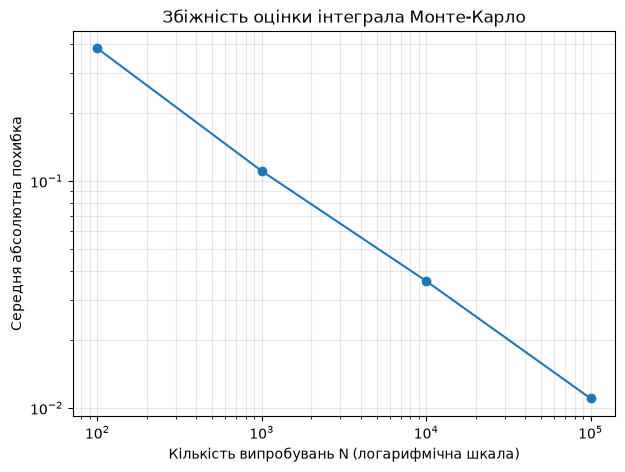

N: 100 → 1000; похибка зменшилась у 3.47 раза (орієнтир для ×10 по N: √10 ≈ 3.16).
N: 1000 → 10000; похибка зменшилась у 3.05 раза (орієнтир для ×10 по N: √10 ≈ 3.16).
N: 10000 → 100000; похибка зменшилась у 3.29 раза (орієнтир для ×10 по N: √10 ≈ 3.16).


In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sample_sizes, mean_absolute_errors, marker="o")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Кількість випробувань N (логарифмічна шкала)")
ax.set_ylabel("Середня абсолютна похибка")
ax.set_title("Збіжність оцінки інтеграла Монте-Карло")
ax.grid(True, which="both", alpha=0.3)
plt.show()

for n1, n2, e1, e2 in zip(sample_sizes[:-1], sample_sizes[1:], mean_absolute_errors[:-1], mean_absolute_errors[1:]):
    print(f"N: {n1} → {n2}; похибка зменшилась у {e1/e2:.2f} раза (орієнтир для ×10 по N: √10 ≈ {np.sqrt(10):.2f}).")

Крива спадає зі збільшенням N. На кожному переході N зростає в 10 разів, а середня похибка зменшується приблизно у 3.05–3.47 раза — близько до теоретичного орієнтира `√10 ≈ 3.16`. На логарифмічних осях це узгоджується зі спаданням порядку `N⁻¹/²`; обмежена кількість повторів дає випадкові відхилення від ідеальної кривої.

## Завдання 5. Закон великих чисел і центральна гранична теорема

Монте-Карло оцінка інтеграла є вибірковим середнім значень `2X³`, де `X` — рівномірна випадкова величина на `[0,2]`. **Закон великих чисел** гарантує, що це середнє збігається до сподівання, яке дорівнює інтегралу. Центральна гранична теорема описує приблизну форму розподілу оцінки біля істинного значення для великого N; сама збіжність до цілі спирається на закон великих чисел.

Якщо стандартне відхилення одного доданка дорівнює `σ`, стандартна похибка середнього дорівнює `σ/√N`. Тому збільшення N у 100 разів збільшує знаменник у `√100=10` разів і зменшує типовий масштаб похибки приблизно в 10 разів, а не в 100. Це безпосередній наслідок властивостей вибіркового середнього незалежних випадкових спостережень, а не окрема магічна властивість Монте-Карло.

## Контрольні питання

1. **Чому оцінка Монте-Карло — вибіркове середнє?** Для інтеграла `I=(b−a)E[f(X)]`, де X рівномірна на `[a,b]`; отже оцінюємо сподівання `f(X)` вибірковим середнім і множимо на довжину інтервалу. Закон великих чисел гарантує збіжність до точного інтеграла зі зростанням N.
2. **Чому вчетверо більше випробувань — лише вдвічі менша похибка?** Стандартна похибка середнього пропорційна `1/√N`. Якщо N множиться на 4, `√N` множиться лише на 2, тож типовий масштаб похибки зменшується вдвічі.
3. **Чому для задачі площі множать на площу охоплювального прямокутника?** Частка точок усередині фігури оцінює відношення `площа фігури / площа прямокутника`. Щоб отримати шукану площу, частку треба помножити на площу прямокутника.
4. **Навіщо `.min(axis=1)` або `.max(axis=1)` у задачі сподівання?** Рядок матриці містить усі кидки в одному випробуванні, тому `axis=1` дає мінімум/максимум окремо для кожного рядка, а потім можна усереднити ці результати. Без `axis` обчислюється одне глобальне значення для всієї матриці, а не вибірка результатів випробувань.

## Підсумок

Для варіанта N=3 (Одеса) методом Монте-Карло оцінено `∫₀² x³ dx`, оцінку при N=1000 порівняно з точним значенням 4, а середні похибки 200 повторів показали спадання, близьке до `1/√N`. Це прямо узгоджується із законом великих чисел і формулою стандартної похибки вибіркового середнього.